# Домашнее задание 1: Градиентный спуск и знакомство с PyTorch

### Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов и высчитывается по формуле min{10; ваш балл}. Сдавать задание после указанного срока сдачи нельзя. 

**Дедлайны:**

- Мягкий дедлайн: 2 недели от даты выдачи.

- Жесткий дедлайн: 3 недели от даты выдачи.

- Штрафа за просрочку после мягкого дедлайна нет.

- Работы, присланные позже жесткого дедлайна, не принимаются.

**Плагиат и Оценивание**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Ответы на вопросы в ноутбуке (поле «Ваш ответ») обязательны: задание без ответа на относящийся к нему вопрос не принимается.

**Защиты**

Итоговая оценка за ДЗ зависит от результатов устной защиты работы проверяющему. Защищаются только те задания, которые были сделаны ДЗ, и теория, необходимая для их реализации. 

### Общая информация
Цели работы:
1. Повторим базу и напишем своими руками градиентный спуск и его модификации (SGD, Momentum).
2. Познакомимся с PyTorch: тензоры, автоматическое дифференцирование (autograd) и первый цикл обучения модели.

Структура и баллы:
- **Часть 1. Градиентный спуск** — 6 баллов (+ бонусы)
- **Часть 2. Знакомство с PyTorch** — 4 балла

Полезные материалы будут сопровождать вас по ходу работы.

**Дисклеймер:**

Если скелет вас только пугает, сбивает и т.д., вы можете его убрать и написать всё самостоятельно с нуля. Главное $-$ придерживаться условия заданий.

# Часть 1. Градиентный спуск (6 баллов)

В этом задании две части $-$ теоретическая и практическая. Теорию можно набирать, используя LaTex, или просто решать на листочке, сфотографировать и отправить вместе с заполненным ноутбуком.

## Теория (1.5 балла)

**Напоминание**: градиентный спуск — метод оптимизации, основанный на том, что отрицательный градиент указывает направление наибольшего убывания функции. Для функции $f(x)$ одношаговый градиентный спуск выглядит как:

$$x_{t+1} = x_t - \eta \nabla f(x_t)$$

Где $\eta$ — learning rate (шаг). Для многомерных функций аналогично.

**Полезные ссылки:**

- Bishop, "Pattern Recognition and Machine Learning" (глава о оптимизации).
- Краткое руководство: https://ml-cheatsheet.ru/gradient-descent/
- Официальный tutorial по оптимизации: https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html


### **Задание 1** (0.6 балла)
* Найдите экстремумы следующих функций (вручную, где возможно) и укажите их тип (максимум, минимум);
* Найдите точки перегиба функций (вручную, где возможно)

1) $f(x) = x^2 - 30x + 1$

2) $g(x) = -x^3 + 5x - 7x^2 + 17$

3) $h(x) = x^2 - 1/x$

4) $j(x) = 1/x^5 + x^{17} + 8$

---

**Краткая справка: экстремумы и перегибы**

**Экстремумы (локальные максимумы и минимумы).**

Точка $x_0$ называется *критической*, если первая производная в ней равна нулю $f'(x_0) = 0$. Для функций нескольких переменных это точки, где все частные производные равны нулю.

Критические точки являются кандидатами на локальные экстремумы, но это не все такие точки:

- Если $f'(x_0) = 0$ и $f''(x_0) > 0$, то в $x_0$ — **локальный минимум**.  
- Если $f'(x_0) = 0$ и $f''(x_0) < 0$, то в $x_0$ — **локальный максимум**.  
- Если $f'(x_0) = 0$ и $f''(x_0) = 0$, требуется дополнительный анализ (возможно, **седловая точка** - является одновременно точкой локального максимума по одному направлению и точкой локального минимума по другому направлению).

> Соответственно, алгоритм поиска локальных экстремумов: ищем производную функции -> приравниваем к нулю, решаем уравнение и получаем критические точки -> проверяем знак производной (от этого зависит max/min) или используем вторую производную для проверки (если равно 0, нужно доп. исследование)

---

**Перегиб**

Пусть $a < b < c$. Пусть на промежутке $a < b$ функция $f$ выпукла, а на промежутке $b < c$ функция $f$ вогнута. Тогда точка $b$ называется **точкой перегиба** (то есть функция меняет знак выпуклости в этой точке). Пример: точка 0 является точкой перегиба для функции $f(x) = x^3$.

Необходимое условие точки перегиба для дважды дифференцируемой функции: $f′′(c) = 0$

То есть практически ищут точки, где $f''(x_0) = 0$, и проверяют изменение знака $f''$ по обе стороны от этой точки.  
Если знак действительно меняется, то в $x_0$ находится точка перегиба.


> Соответственно, алгоритм поиска точек перегиба: ищем вторую производную -> приравниваем нулю и решаем уравнение (либо получаем точки, где она не существует) -> проверяем смену знака


---

**Ваше решение:**

### **Задание 2** (0.6 балла)
Найдите экстремумы и точки перегиба этих функций в Python.

*Справка*:
> Sympy $-$ библиотека для символьных вычислений (математика "на бумаге", но в коде). Умеет в производные, интегралы, пределы, уравнения, матрицы, многочлены и т.д.

Пример запуска (функция $f(x) = x^2$):

In [ ]:
import sympy as sp

# объявляем переменную
x = sp.Symbol('x')

# задаём функцию
f = x**2

# производная
f_prime = sp.diff(f, x)

# выводим результаты
print("f(x) =", f)
print("f'(x) =", f_prime)

Теперь переходим к решению ранее озвученного задания

In [ ]:
import sympy as sp
import numpy as np
from enum import Enum

# your code here

### Задание 3 (0.3 балла)
Постройте графики вышеупомянутых функций (не забудьте подписать оси и сами графики):
*   изобразите графики с подписанными осями
*   отметьте одним цветом локальные экстремумы
*   отметьте другим цветом точки перегиба
*   подпишите на оси x значения экстремумов и точек перегиба

Подсказка: для того, чтобы отметить точку на графике, вам понадобится функция (plt.scatter), а для того, чтобы подписать её значение на оси (plt.annotate).

Пример хорошего графика:

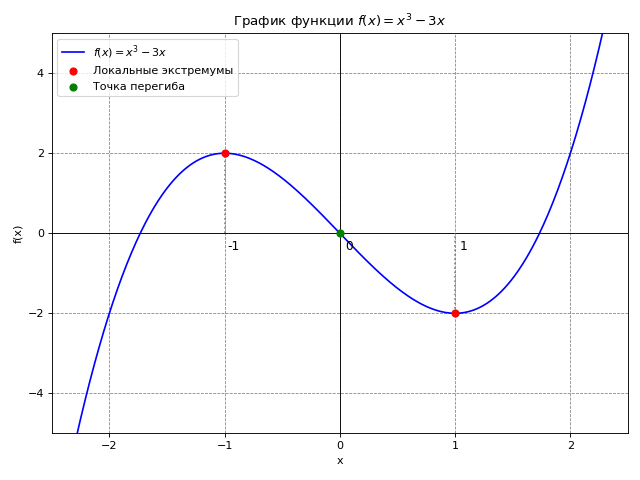

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Скелет для примера: заполните нужными значениями, а далее повторите с другими функциями.
# Функцию называем f_np, чтобы не перепутать её с sympy-выражениями из задания 2.

def f_np(x):
    return x**2 - 30*x + 1

# TODO: подберите диапазон по x так, чтобы были видны все особые точки
x_values = 
y_values = 

# TODO: координаты точки минимума, найденные в заданиях 1-2
x_min, y_min = 

# Создаём окно для графика
plt.figure(figsize=(8, 8))

# Рисуем координатные оси для наглядности
plt.axvline(x=0, c='black')
plt.axhline(y=0, c='black')
# Добавляем сетку для удобства чтения графика
plt.grid(color='gray', linestyle='--', linewidth=0.7)

# TODO: ограничьте диапазон отображаемых значений
plt.xlim(..., ...)
plt.ylim(..., ...)

# Подписываем оси
plt.xlabel('x')
plt.ylabel('f(x)')

# Подписываем значение x-координаты минимума под точкой
plt.annotate(f'{x_min:.2f}', (x_min, y_min), textcoords="offset points", xytext=(0, -15), ha='center')
# Отмечаем на графике найденную точку минимума
plt.scatter(x_min, y_min, label='Точка минимума', color='red', s=20)

plt.title('График функции f(x)')
plt.plot(x_values, y_values, label='f(x) = $x^2 - 30x + 1$', color='blue')
plt.legend()
plt.show()

## Практика: часть 1 (2 балла + бонус)

### Задание 4 (0.75 балла).
Допишите функцию `gradient_descent`, которая ищет минимум функции одной переменной методом градиентного спуска:

* реализуйте шаг метода по формуле $x_{t+1} = x_t - \eta f'(x_t)$;
* добавьте **два условия останова**:
    1. производная почти равна нулю: $|f'(x_t)| < \delta$ (мы пришли в точку экстремума);
    2. точка почти перестала двигаться: $|x_{t+1} - x_t| < \varepsilon$;
* функция должна возвращать найденную точку и траекторию `trace` — список всех $x_t$ (она понадобится для графиков).

Функция принимает на вход sympy-выражение (как в задании 2). Чтобы не вызывать медленный `subs` на каждой итерации, производная заранее превращается в обычную python-функцию с помощью `sp.lambdify`.

In [ ]:
import sympy as sp

x = sp.Symbol('x')

def gradient_descent(f_expr, x_start, learning_rate, epsilon, delta, num_iterations):
    """
    f_expr         — функция, заданная sympy-выражением от x (например, x**2 - 30*x + 1)
    x_start        — начальная точка
    learning_rate  — шаг градиентного спуска (eta)
    epsilon        — порог останова по изменению точки
    delta          — порог останова по модулю производной
    num_iterations — максимальное число итераций

    Возвращает: (найденная точка, список всех точек trace)
    """
    df = sp.lambdify(x, sp.diff(f_expr, x))  # производная как обычная python-функция

    x_curr = x_start
    trace = [x_curr]

    for i in range(num_iterations):
        grad_value = df(x_curr)

        # TODO: условие останова (1) — если |grad_value| < delta, выходим из цикла

        # TODO: вычислите x_new по формуле градиентного спуска,
        # используя текущее значение (x_curr), размер шага (learning_rate) и производную (grad_value)
        # x_new = ...

        trace.append(x_new)

        # TODO: условие останова (2) — если |x_new - x_curr| < epsilon, выходим из цикла

        x_curr = x_new

    return x_curr, trace

### Задание 5 (0.75 балла).

Подберите начальное приближение (сделайте несколько запусков из случайной начальной точки) и шаг градиентного спуска таким образом, чтобы процедура выдавала правильное значение наименьшего локального минимума функций (если он есть):
1. В качестве результата выведите на экран значение начального приближения ($x_0$), `learning_rate`
2. Нарисуйте график функции и изобразите на нём наименьший из найденных локальных минимумов; на оси $x$ подпишите значение этого минимума. \
(Постарайтесь сделать реализацию графика в виде функции, чтобы оптимизировать процесс. Потом функция понадобится вам в задании 6, но это не обязательное требование).
3. Если такой точки у функции нет (например, функция не ограничена снизу), поясните это текстом при помощи Markdown

**Обратите внимание:** функции $h(x)$ и $j(x)$ не определены в точке $x = 0$. Если шаг градиентного спуска «перепрыгнет» через ноль, метод окажется на другой ветви графика и может разойтись. Попробуйте стартовать с разных сторон от нуля и с разными `learning_rate` и опишите, что наблюдаете.

Пример графика:

In [ ]:
# Пример простого графика с отметками для функции f(x) = x^3 - 3x
# Attention! Вам в идеале нужно сделать это через функцию для оптимизации и последующего задания.
# Здесь используем свои имена (x_s, f_example), чтобы не перезаписать x и функции из заданий выше.

x_s = sp.symbols('x')
f_example = x_s**3 - 3*x_s
f1 = sp.diff(f_example, x_s)
f2 = sp.diff(f1, x_s)

crit = sp.solve(sp.Eq(f1, 0), x_s)   # экстремумы
infl = sp.solve(sp.Eq(f2, 0), x_s)   # кандидаты на перегиб

f_example_np = sp.lambdify(x_s, f_example, 'numpy')  # sympy-выражение -> numpy-функция

xx = np.linspace(-3, 3, 400)
yy = f_example_np(xx)
plt.figure(figsize=(7, 4))
plt.plot(xx, yy, label='f(x)=x^3-3x')

# отметки экстремумов
for c in crit:
    xc = float(c)
    plt.scatter([xc], [f_example_np(xc)], marker='o')
    plt.text(xc, f_example_np(xc), f'  extremum (x={xc:.2f})')

# отметка перегиба
for p in infl:
    xp = float(p)
    plt.scatter([xp], [f_example_np(xp)], marker='x')
    plt.text(xp, f_example_np(xp), f'  inflection (x={xp:.2f})')

plt.axhline(0, color='k', linewidth=0.5)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def plot_trace(f_expr, x_found, trace=None, x_range=(-10, 10), title=''):
    """
    Рисует график функции f_expr (sympy-выражение от x), отмечает найденный минимум x_found
    и подписывает его значение на оси x. По желанию — отрисовывает траекторию trace.
    """
    # TODO: можно частично опираться на скелет из задания 3
    pass

Применение: выводим ($x_0$), `learning_rate` и график с помощью кода ниже

In [ ]:
import random

# TODO: подберите начальную точку и шаг
# x_start = random.uniform(..., ...)
# learning_rate = ...
epsilon = 1e-6
delta = 1e-3
num_iterations = 1000

# TODO: для каждой функции из задания 1:
#   запускаем gradient_descent, вычисляем значение функции в найденной точке минимума,
#   выводим x_start и learning_rate, строим график с помощью plot_trace

# your code here

### Задание 5.1 (0.5 балла). Траектории градиентного спуска

Посмотрим своими глазами, как размер шага влияет на работу метода. Возьмите функцию $f(x) = x^2 - 30x + 1$ из задания 1 и одну и ту же начальную точку $x_0$. Подберите три значения `learning_rate`:

* **слишком маленький** — за разумное число итераций метод так и не дошёл до минимума;
* **нормальный** — метод быстро и спокойно сходится;
* **слишком большой** — метод «прыгает» через минимум всё дальше и расходится.

Для каждого значения запустите `gradient_descent` из задания 4 и постройте два графика рядом:

1. график функции $f(x)$, на котором точками, соединёнными линией, показана траектория `trace` (для каждого `learning_rate` — свой цвет);
2. значение $x_t$ в зависимости от номера итерации $t$ (горизонтальной линией отметьте настоящий минимум).

*Подсказки:* при слишком большом шаге значения быстро улетают в бесконечность, поэтому для этого запуска ограничьте число итераций (например, 10–20) и задайте пределы осей через `plt.xlim` / `plt.ylim`. Если найдёте «промежуточный» шаг, при котором метод сходится, но с колебаниями вокруг минимума, — покажите и его.

Графики пригодятся для ответа на вопрос ниже.

In [ ]:
# TODO: подберите три значения learning rate
learning_rates = {
    'слишком маленький': ...,
    'нормальный': ...,
    'слишком большой': ...,
}
x_start = ...   # одна и та же начальная точка для всех запусков

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

for name, lr in learning_rates.items():
    # TODO: запустите gradient_descent из задания 4 (для слишком большого шага — с небольшим num_iterations)
    # TODO: на axs[0] нарисуйте траекторию поверх графика функции
    # TODO: на axs[1] нарисуйте x_t в зависимости от номера итерации
    pass

# TODO: график самой функции на axs[0], линия настоящего минимума на axs[1],
#       подписи осей, заголовки, легенды, пределы осей

plt.show()

### **Вопрос:**

Почему слишком большой learning rate может приводить к расходимости алгоритма, а слишком маленький — к медленной сходимости? Опишите кратко, опираясь на графики из задания 5.1.

**Ваш ответ:**

```
```
**Ответ нейросети:**

### Задание 6 $-$ бонус (0.5 балла).

* Реализуйте [метод Ньютона](https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization) (метод второго порядка) для поиска минимума функции. Про метод ещё можно почитать [здесь](https://math.semestr.ru/optim/minimum.php).
* Примените метод Ньютона для поиска минимума указанных функций (в ответе выведите подходящее значение начальной точки, график с найденным и подписанным значением минимума, как в задании 5).

In [ ]:
# your code here

### Бонус к заданию 6 (0.25 балла).
Сравните скорость работы градиентного спуска и метода Ньютона при одинаковой точности решения $|x_{found}-x_{true}|<10^{-5}$:
* за сколько итераций каждый метод сходится (в среднем по всем функциям для правильно подобранных значений гиперпараметров)? Какой быстрее?
* какой метод дает более точный результат при фиксированном числе итераций $N=10$? (для ответа на этот вопрос добавьте в процедуру градиентного спуска возможность останавливаться при достижении некоторого количества итераций $N$)

In [ ]:
# your code here

## Практика: часть 2 (2.5 балла + бонус)

**Напоминание:**
* MSE в матричном виде: $Q(w) = \dfrac{1}{\ell} \left( y - Xw \right)^T \left( y - Xw \right)$ ($\ell$ - кол-во объектов)
* Тогда его градиент будет: $\triangledown_wQ = \dfrac{-2}{\ell}X^T\big(y - Xw\big)$

### **Вопрос:**
Выведите эту формулу для градиента MSE.

**Ваш ответ:**

**Ответ нейросети:**

### Задание 7 (1 балл).
Реализуйте линейную регрессию с функцией потерь MSE, обучаемую с помощью:

* Градиентного спуска (0.3 балла);

* Стохастического градиентного спуска (0.3 балла);

* Метода Momentum (0.4 балла)


Во всех пунктах необходимо соблюдать следующие условия:

* Все вычисления должны быть векторизованы;
* Циклы средствами python допускается использовать только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):

    * проверку на евклидову норму разности весов на двух соседних итерациях (например, меньше некоторого малого числа порядка $10^{-6}$, задаваемого параметром `tolerance`);
    * достижение максимального числа итераций (например, 10000, задаваемого параметром `max_iter`).
* Чтобы проследить, что оптимизационный процесс действительно сходится, будем использовать атрибут класса `loss_history` — в нём после вызова метода `fit` должны содержаться значения функции потерь (MSE на **всей** обучающей выборке) для всех итераций, начиная с первой (до совершения первого шага по антиградиенту);
* Инициализировать веса можно случайным образом или нулевым вектором.
* Свободный член отдельно не заводим: в задании 8 мы добавим к матрице признаков столбец из единиц, и вес при нём как раз и будет свободным членом.

Ниже приведены шаблоны классов. `GradientDescent` — базовый класс, `SGD` и `Momentum` наследуют его и переопределяют нужные методы.

**Что нужно реализовать:**

Класс `GradientDescent` (базовый, полный градиентный спуск):
- `calc_loss(X, y)` — MSE при текущих весах;
- `calc_gradient(X, y)` — градиент MSE по весам (формула выше);
- `fit(X, y)` — обучение на всём наборе данных;
- `predict(X)` — прогноз.

Класс `SGD` — наследует `GradientDescent`:
- добавляется аргумент `batch_size`;
- в `fit` на каждой итерации градиент считается не по всей выборке, а по случайному мини-батчу из `batch_size` объектов.

Класс `Momentum` — наследует `SGD`:
- добавляется аргумент `beta` (коэффициент импульса);
- в `fit` используется «скорость» $v$ — накопленное среднее градиентов:
  $$
  v_t = \beta v_{t-1} + (1 - \beta) \nabla L, \quad
  w_{t+1} = w_t - \eta v_t
  $$
- если передать `batch_size`, равный размеру выборки, получится полный градиентный спуск с импульсом.

> В PyTorch (и в следующем ДЗ) momentum записывается чуть иначе: $v_t = \beta v_{t-1} + \nabla L$, без множителя $(1-\beta)$. Это та же идея, отличается только масштаб шага.

In [ ]:
import numpy as np


class GradientDescent:
    """
    Линейная регрессия с MSE, обучаемая полным градиентным спуском.

    eta       : float — скорость обучения (learning rate)
    max_iter  : int — максимальное число итераций
    tolerance : float — порог останова по норме разности весов на соседних итерациях
    w0        : np.ndarray или None — начальные веса (если None — нулевой вектор)
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None):
        self.eta = eta
        self.max_iter = max_iter
        self.tolerance = tolerance
        self.w0 = w0
        self.w = None
        self.loss_history = []

    def calc_loss(self, X, y):
        """
        X: np.ndarray формы (ell, d), y: np.ndarray формы (ell,)
        Возвращает: float — MSE при текущих весах self.w
        """
        # your code here
        pass

    def calc_gradient(self, X, y):
        """
        X: np.ndarray формы (ell, d) (ell может быть равен размеру батча), y: np.ndarray формы (ell,)
        Возвращает: np.ndarray формы (d,) — градиент MSE по весам
        """
        # your code here
        pass

    def fit(self, X, y):
        """
        X: np.ndarray формы (ell, d), y: np.ndarray формы (ell,)
        Не забудьте:
          - инициализировать self.w (из w0 или нулями) и очистить self.loss_history;
          - на каждой итерации сначала сохранить loss, затем сделать шаг;
          - остановиться, если ||w_new - w_old|| < tolerance или достигнут max_iter.
        Возвращает: self
        """
        # your code here
        return self

    def predict(self, X):
        if self.w is None:
            raise Exception('Not trained yet')
        # your code here
        pass


class SGD(GradientDescent):
    """
    Стохастический градиентный спуск: градиент считается по случайному мини-батчу.
    batch_size : int — размер мини-батча
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1):
        super().__init__(eta, max_iter, tolerance, w0)
        self.batch_size = batch_size

    def fit(self, X, y):
        # TODO: как в GradientDescent.fit, но на каждой итерации:
        #   - выберите случайные индексы мини-батча (np.random.choice)
        #   - посчитайте градиент только по батчу
        #   - loss в loss_history считайте по всей выборке
        # your code here
        return self


class Momentum(SGD):
    """
    SGD с импульсом.
    beta : float — коэффициент импульса
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1, beta=0.9):
        super().__init__(eta, max_iter, tolerance, w0, batch_size)
        self.beta = beta

    def fit(self, X, y):
        # TODO: как в SGD.fit, но шаг делается по «скорости» v (см. формулу выше)
        # your code here
        return self

### **Задание 8 (0 баллов)**.
* Загрузите данные [NYC Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/data) — файл `train.csv` (для скачивания нужен аккаунт Kaggle и принятие правил соревнования);
* Удалите столбцы `id` и `dropoff_datetime` — время окончания поездки «подсказывает» ответ (это утечка целевой переменной);
* Из `pickup_datetime` получите час и день недели поездки, `store_and_fwd_flag` переведите в 0/1. В итоге в матрице признаков должны остаться только числа. По желанию добавьте расстояние между точками посадки и высадки — это заметно улучшит качество;
* Разбейте выборку на обучающую и тестовую в отношении 7:3 с `random_state=0`;
* Отмасштабируйте признаки с помощью `StandardScaler` (обучайте его только на train!) — без этого градиентный спуск будет сходиться очень плохо;
* Добавьте к матрицам признаков столбец из единиц (свободный член);
* Преобразуйте целевую переменную `trip_duration` как $\hat{y} = \log{(y + 1)}$.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# your code here

### Вопрос:
Что такое $R^2$?

**Ответ нейросети:**

**Ваш ответ:**

### Задание 9 (1 балл).

Обучите и провалидируйте модели на данных из предыдущего пункта, сравните качество между методами по метрикам MSE и $R^2$. Исследуйте влияние параметров `max_iter` и `eta` (для SGD — ещё `batch_size`, для Momentum — ещё `beta`) на процесс оптимизации. Согласуется ли оно с вашими ожиданиями?

*Подсказка*:

Подбирайте `eta` **по логарифмической шкале** — это помогает быстрее найти разумный диапазон значений.  
Можно использовать `numpy.logspace` для создания набора значений от, например, `1e-4` до `1`:

In [ ]:
# Пример: 5 значений eta от 1e-4 до 1 в логарифмической шкале
etas = np.logspace(-4, 0, 5)
print(etas)
# должно получиться [0.0001 0.001 0.01 0.1 1.0]

In [ ]:
# your code here

### Задание 10 (0.5 балла).
Постройте графики (на одной и той же картинке) зависимости величины функции потерь от номера итерации для полного и стохастического градиентного спуска, а также для метода Momentum. Сделайте выводы о скорости сходимости различных модификаций градиентного спуска.

Не забывайте о том, что должны получиться *красивые* графики! :)

In [ ]:
# your code here

### Задание 10.1 $-$ бонус (0.5 балла). Уменьшающийся шаг для SGD

На графиках из задания 10 видно, что SGD с постоянным шагом не «успокаивается»: loss продолжает дёргаться вокруг минимума, потому что градиент по мини-батчу шумный. Популярный способ это исправить — постепенно **уменьшать шаг** по ходу обучения:

$$
\eta_t = \frac{\eta_0}{(t + 1)^{p}},
$$

где $t$ — номер итерации (с нуля), $\eta_0$ — начальный шаг, $p \geq 0$ — скорость уменьшения ($p = 0$ — обычный SGD с постоянным шагом).

1. Допишите класс `SGDDecay` ниже.
2. Обучите SGD с $p = 0$, $p = 0.5$ и $p = 1$ на данных из задания 8. Для каждого $p$ подберите свой $\eta_0$ по логарифмической сетке.
3. Нарисуйте кривые loss для лучших вариантов на одном графике и сравните итоговое качество на тесте (MSE и $R^2$).

*Подсказка:* при уменьшающемся шаге веса меняются всё медленнее, и критерий останова по `tolerance` может сработать слишком рано. Проверьте, не происходит ли этого у вас, и если да — учтите это (например, уменьшите `tolerance`).

In [ ]:
class SGDDecay(SGD):
    """
    SGD с уменьшающимся шагом
    где t — номер итерации (с нуля).
    power = 0 — обычный SGD с постоянным шагом.
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1, power=0.5):
        super().__init__(eta, max_iter, tolerance, w0, batch_size)
        self.power = power

    def fit(self, X, y):
        # your code here
        return self

In [ ]:
# TODO: подберите eta для power = 0, 0.5, 1, постройте кривые loss на одном графике,
#       сравните MSE и R^2 на тесте

# your code here

### **Вопрос:**

Для сходимости SGD к минимуму последовательность шагов $\eta_t$ должна удовлетворять **условиям Роббинса–Монро**. Сформулируйте их и объясните простыми словами, зачем нужно каждое из условий. Какие из ваших расписаний ($p = 0$, $p = 0.5$, $p = 1$) им удовлетворяют? Согласуется ли это с тем, что вы увидели на графиках?

**Ответ нейросети:**

```
```
**Ваш ответ:**


### Задание $-$ бонус (0.25 балла).
Реализуйте линейную регрессию с функцией потерь MSE, обучаемую с помощью метода
[Adam](https://arxiv.org/pdf/1412.6980.pdf) $-$ добавьте при необходимости параметры в класс модели, повторите предыдущие два пункта и сравните результаты.

In [ ]:
# your code here

# Часть 2. Знакомство с PyTorch (4 балла)

**PyTorch** — самая популярная библиотека для обучения нейросетей. С ней мы будем работать весь курс. Главное, что она умеет:

- работать с многомерными массивами — **тензорами** (`torch.Tensor`). Они очень похожи на `numpy.ndarray`, но умеют считаться на видеокарте;
- **автоматически считать производные** (autograd). В первой части вы выводили градиенты руками — PyTorch делает это сам.

Ключевые идеи autograd:

- `requires_grad=True` — просим PyTorch запоминать операции с тензором, чтобы потом посчитать производную по нему;
- `y.backward()` — посчитать производные скалярного значения `y` по всем тензорам с `requires_grad=True`; результат попадёт в их атрибут `.grad`;
- `with torch.no_grad():` — временно отключаем запоминание операций (нужно, например, когда мы сами обновляем параметры).

**Ссылки, которые могут оказаться полезными:**

- Официальный туториал PyTorch: https://pytorch.org/tutorials/beginner/basics/intro.html
- Туториал по autograd: https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html

### Задание 11 (0.5 балла). Тензоры

Выполните по шагам (каждый шаг — одна-две строчки кода, выводите результат через `print`):

1. Создайте тензор `a` из списка `[[1, 2, 3], [4, 5, 6]]` с типом `torch.float32`, выведите его форму (`shape`) и тип (`dtype`);
2. Создайте тензор `b` размера $3 \times 2$ из случайных чисел (`torch.randn`);
3. Посчитайте матричное произведение `a` и `b` (оператор `@`) и поэлементное произведение `a` на само себя (`*`);
4. Посчитайте сумму и среднее `a` по строкам (аргумент `dim`);
5. Переведите `a` в numpy-массив и обратно (`.numpy()`, `torch.from_numpy`);
6. Измените форму `a` на $3 \times 2$ (`reshape`).

In [ ]:
import torch
import numpy as np

# your code here

### Задание 12 (1 балл). Autograd

1. Возьмите функцию $f(x) = x^2 - 30x + 1$ из первой части. Создайте тензор `x` со значением `5.0` и `requires_grad=True`, посчитайте `y = f(x)`, вызовите `y.backward()` и выведите `x.grad`. Совпадает ли результат с производной, которую вы нашли в задании 2?
2. Проверьте формулу градиента MSE, которую вы выводили в первой части: $\nabla_w Q = \dfrac{-2}{\ell} X^T (y - Xw)$. Для этого посчитайте MSE на данных из ячейки ниже, вызовите `backward()` и сравните `w.grad` с градиентом, посчитанным по формуле (используйте `torch.allclose`).

In [ ]:
# 1. Производная f(x) = x^2 - 30x + 1 в точке x = 5

# your code here

In [ ]:
# 2. Проверяем формулу градиента MSE
torch.manual_seed(0)
X = torch.randn(100, 3)
y = torch.randn(100)
w = torch.randn(3, requires_grad=True)

# TODO: посчитайте MSE
# TODO: посчитайте градиент по формуле из первой части
# TODO: сравните его с w.grad через torch.allclose

# your code here

### **Вопрос:**

Посчитайте `y = f(x)` и вызовите `y.backward()` два раза подряд (каждый раз заново вычисляя `y`), не обнуляя градиент. Что стало с `x.grad`? Почему в циклах обучения градиенты нужно обнулять на каждом шаге?

**Ответ нейросети:**

```
```
**Ваш ответ:**

In [ ]:
# your code here

### Задание 13 (1 балл). Градиентный спуск через autograd

Перепишите градиентный спуск из задания 4 так, чтобы производную считал PyTorch, а не sympy. Запустите его для функций $f$ и $g$ из первой части с теми же начальными точками и `learning_rate`, что и в задании 5, и сравните результаты: совпадает ли найденная точка и число итераций?

In [ ]:
def gradient_descent_torch(f, x_start, learning_rate, epsilon=1e-6, num_iterations=1000):
    """
    f — функция, которая принимает и возвращает torch-тензор (например, lambda t: t**2 - 30*t + 1)
    Возвращает: (найденная точка (float), траектория — список float)
    """
    x = torch.tensor(float(x_start), requires_grad=True)
    trace = [x.item()]

    for i in range(num_iterations):
        # TODO: вычислите значение функции 
        # TODO: посчитайте производную 
        # TODO: сделайте шаг градиентного спуска внутри блока без градиентов
        # TODO: обнулите градиент:
        # TODO: добавьте x.item() в trace и остановитесь, если условие остановки
        pass

    return x.item(), trace

In [ ]:
# TODO: запустите gradient_descent_torch для f и g, сравните с результатами задания 5

# your code here

### **Вопрос:**

Зачем при обновлении `x` нужен `with torch.no_grad()`? Что будет, если его убрать?

**Ответ нейросети:**

```
```
**Ваш ответ:**

### Задание 14 (1.5 балла). Линейная регрессия на PyTorch

Теперь обучим ту же линейную регрессию, что и в задании 7, но «по-взрослому» — стандартными средствами PyTorch:

- модель — линейный слой `nn.Linear`;
- функция потерь — `nn.MSELoss`;
- оптимизатор — `torch.optim.SGD`.

Именно такой цикл обучения (обнулить градиенты → прогноз → loss → `backward()` → шаг оптимизатора) вы будете писать во всех следующих ДЗ.

Что нужно сделать:
1. Используйте данные такси из задания 8. `nn.Linear` сам добавляет свободный член, поэтому столбец из единиц здесь не нужен (уберите его или создайте слой с `bias=False`);
2. Допишите цикл обучения ниже и обучите модель (на каждой итерации используем всю обучающую выборку — это полный градиентный спуск);
3. Нарисуйте график loss по итерациям, посчитайте MSE и $R^2$ на тесте и сравните с вашей реализацией из задания 9;
4. Замените `torch.optim.SGD` на `torch.optim.Adam` (подберите `lr`) и сравните скорость сходимости.

In [ ]:
import torch.nn as nn

# TODO: переведите данные из задания 8 в тензоры типа float32
#       целевую переменную сделайте формы (N, 1), чтобы она совпадала по форме с выходом модели
X_train_t = ...
y_train_t = ...
X_test_t = ...
y_test_t = ...

model =       # TODO: число признаков
criterion = 
optimizer =    # TODO: подберите lr

num_epochs =   # TODO
loss_history = []

for epoch in range(num_epochs):
    # TODO: 1) обнулите градиенты
    # TODO: 2) прямой проход
    # TODO: 3) посчитайте loss
    # TODO: 4) обратный проход
    # TODO: 5) шаг оптимизатора
    # TODO: 6) сохраните
    pass

In [ ]:
# TODO: график loss, MSE и R^2 на тесте, сравнение с заданием 9; то же самое с Adam

# your code here

### **Вопрос:**

Сопоставьте строчки цикла обучения на PyTorch с тем, что вы писали руками в задании 7. Какая строчка заменяет вычисление градиента? Какая — шаг по антиградиенту? Что делает оптимизатор и почему в вашей реализации из задания 7 такого шага не было?

**Ответ нейросети:**

```
```
**Ваш ответ:**

## Использованные источники

Если вы пользовались чужими решениями, статьями, ответами на форумах и т.п. — перечислите ссылки здесь.

- ...

## Поздравляем, вы прошли игру!
╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ